# AirCast: Predicting Urban Air Quality ($PM_{2.5}$) Using Classical Machine Learning
**Author:** Adrij Sarkar (B.Tech Second Year, IIT Indore)  
**Submission:** CFA Club, IIT Indore — Induction Task 2026 (Problem Statement 3: Analytics)

### 1. Project Framing & Dataset Documentation
* **Source & Citation:** [UCI Machine Learning Repository — Beijing PM2.5 Data (ID 381)](https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data), [DOI: 10.24432/C5JS49](https://doi.org/10.24432/C5JS49), introduced by [Liang et al. (2015), *Proceedings of the Royal Society A*, 471(2182), 20150257](https://royalsocietypublishing.org/rspa/article/471/2182/20150257/57659/Assessing-Beijing-s-PM2-5-pollution-severity).
* **Coverage:** 43,824 hourly observations from `2010-01-01 00:00` to `2014-12-31 23:00` (5 full calendar years).
* **Task Framing (Same-Hour Estimation):** The objective is to estimate hourly $PM_{2.5}$ concentration ($\mu\text{g/m}^3$) from same-hour meteorological readings and calendar information. The dataset contains `year`, `month`, `day`, `hour`, `DEWP`, `TEMP`, `PRES`, `cbwd`, `Iws`, `Is`, and `Ir`; the final model uses the 13 columns in `all_features`, including engineered features. Raw `year` and `day` are not model inputs. This is a contemporaneous environmental estimation task rather than a next-day forecast, and neither current nor lagged $PM_{2.5}$ values are used as inputs in the core pipeline.
* **Known Dataset Limitations:**
  1. *Spatial Mismatch:* $PM_{2.5}$ was recorded at the US Embassy in central Beijing, whereas meteorological variables were measured at Beijing Capital International Airport, so the weather measurements may not fully represent conditions at the pollution sensor.
  2. *Cumulative Wind & Precipitation Definitions:* `Iws` is cumulative wind run (m/s accumulated along a sustained wind direction) rather than instantaneous wind speed, and `Is` / `Ir` represent cumulative hours of snow and rain.
### Running this notebook
Open `aircast.ipynb` from the repository root and run cells in order. Dependencies are `ucimlrepo`, `numpy`, `pandas`, `matplotlib`, `seaborn`, and `scikit-learn`, plus a Jupyter environment. The first cell installs `ucimlrepo`; the dataset is downloaded from UCI, so that step requires internet access. Figures are saved as PNG at 150 dpi in `figures/`; the three comparison/ablation CSVs are saved in the current working directory. Optional JPG copies can accompany the PNGs for convenient viewing. Saved outputs are retained from the submitted notebook.


In [1]:
%pip install -q ucimlrepo

In [2]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Download the dataset from UCI.
dataset = fetch_ucirepo(id=381)

# Combine explanatory variables and the prediction target.
data = pd.concat(
    [dataset.data.features, dataset.data.targets],
    axis=1
).rename(columns={"pm2.5": "PM25"})

# Build a timestamp from the existing date columns.
data["timestamp"] = pd.to_datetime(
    data[["year", "month", "day", "hour"]]
)

data = data.sort_values("timestamp").reset_index(drop=True)

print("Rows and columns:", data.shape)
print("Date range:", data["timestamp"].min(), "to",
      data["timestamp"].max())

print("\nMissing values:")
print(data.isna().sum())

print("\nDuplicate timestamps:",
      data["timestamp"].duplicated().sum())

display(data.head())

Rows and columns: (43824, 13)
Date range: 2010-01-01 00:00:00 to 2014-12-31 23:00:00

Missing values:
year            0
month           0
day             0
hour            0
DEWP            0
TEMP            0
PRES            0
cbwd            0
Iws             0
Is              0
Ir              0
PM25         2067
timestamp       0
dtype: int64

Duplicate timestamps: 0


,year,month,day,hour,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir,PM25,timestamp
0,2010,1,1,0,-21,-11.0,1021.0,NW,1.79,0,0,NaN,2010-01-01 00:00:00
1,2010,1,1,1,-21,-12.0,1020.0,NW,4.92,0,0,NaN,2010-01-01 01:00:00
2,2010,1,1,2,-21,-11.0,1019.0,NW,6.71,0,0,NaN,2010-01-01 02:00:00
3,2010,1,1,3,-21,-14.0,1019.0,NW,9.84,0,0,NaN,2010-01-01 03:00:00
4,2010,1,1,4,-20,-12.0,1018.0,NW,12.97,0,0,NaN,2010-01-01 04:00:00


In [3]:
# Retain only observations with a measured prediction target.
labelled = data.dropna(subset=["PM25"]).copy()

# Split by time before fitting any preprocessing or models.
train = labelled.loc[labelled["year"] <= 2012].copy()
validation = labelled.loc[labelled["year"] == 2013].copy()
test = labelled.loc[labelled["year"] == 2014].copy()

print("Original rows:", len(data))
print("Rows with measured PM2.5:", len(labelled))
print("Rows excluded:", len(data) - len(labelled))

for name, frame in [
    ("Training", train),
    ("Validation", validation),
    ("Final test", test),
]:
    print(
        f"{name}: {len(frame):,} rows | "
        f"{frame['timestamp'].min()} to "
        f"{frame['timestamp'].max()}"
    )

Original rows: 43824
Rows with measured PM2.5: 41757
Rows excluded: 2067
Training: 24,418 rows | 2010-01-02 00:00:00 to 2012-12-31 23:00:00
Validation: 8,678 rows | 2013-01-01 00:00:00 to 2013-12-31 23:00:00
Final test: 8,661 rows | 2014-01-01 00:00:00 to 2014-12-31 23:00:00


### Step 1 Interpretation: Data Integrity, Chronological Split, and Missingness Analysis

* **Observed Facts:**
  * The raw dataset `data` contains exactly `43,824` rows and `13` columns covering every hour from 2010 to 2014 with `0` duplicate timestamps.
  * Target `PM25` is missing in `2,067` rows (`4.72%`), while all meteorological and calendar columns are `100%` complete. Dropping unlabelled target rows leaves `labelled` with `41,757` rows, partitioned chronologically into `train` (2010–2012, `n = 24,418`), `validation` (2013, `n = 8,678`), and `test` (2014, `n = 8,661`).
  * Within the 2010–2012 training window (`26,304` total calendar hours), `1,886` hours (`7.17%`) lack `PM25`. Missingness is relatively even across hours of the day (`6.4%` to `8.1%`) and years (`7.64%` in 2010, `8.31%` in 2011, `5.57%` in 2012), but varies sharply by calendar month—ranging from `0.34%` in February to `16.26%` in August (`10.62%` in January, `11.99%` in September).
  * Missing hours cluster into `144` contiguous blocks (median length `2` hours, with the five longest spans lasting `155`, `127`, `99`, `91`, and `76` consecutive hours).
  * In `train`, `PM25` has mean `97.82`, standard deviation `89.25`, median `73.0`, IQR `111.0` (`Q1 = 28`, `Q3 = 139`), range `0` to `994`, and right-skewness `1.70`. Physical sanity checks show `0` negative `PM25` values, `0` non-positive pressures (`PRES` spans `992` to `1045` hPa), and `0` negative `Iws`/`Is`/`Ir` values. Exactly `1` row has `DEWP > TEMP` (`2010-10-08 07:00`, `DEWP = 13`, `TEMP = 12`, `PM25 = 349`), possibly due to measurement precision or recording error; its cause is unconfirmed; `2` rows have `PM25 == 0` and `139` rows have `PM25 <= 5`.
* **Hypotheses:**
  * Multi-day missing blocks (up to 155 hours) may reflect sensor maintenance or telemetry outages. The dataset does not establish their cause; missingness varies across months. Whether pollution during outage hours was systematically higher or lower cannot be verified from the dataset alone.
* **Conclusions & Decisions:**
  * Unlabelled target rows are excluded rather than imputed so that models are never trained or evaluated on synthetic target values, while noting that summer months (especially August) are slightly under-represented in `train`. The single `DEWP > TEMP` row and low `PM25` readings are retained because these checks alone do not establish that they are erroneous. The dew-point discrepancy remains a documented data-quality uncertainty.

In [4]:
# Inspect types and distributions using training data only.
print("Column types:")
print(train.dtypes)

numeric_columns = [
    "PM25", "TEMP", "DEWP", "PRES", "Iws", "Is", "Ir"
]

print("\nTraining-data summary:")
display(train[numeric_columns].describe().round(2))

# Flag obvious issues without automatically deleting anything.
checks = pd.Series({
    "Negative PM2.5": (train["PM25"] < 0).sum(),
    "Non-positive pressure": (train["PRES"] <= 0).sum(),
    "Negative cumulative wind measure": (train["Iws"] < 0).sum(),
    "Negative snow hours": (train["Is"] < 0).sum(),
    "Negative rain hours": (train["Ir"] < 0).sum(),
    "Dew point above temperature": (
        train["DEWP"] > train["TEMP"]
    ).sum(),
})

print("\nValues requiring inspection:")
display(checks)

print("\nWind-direction categories:")
print(train["cbwd"].value_counts(dropna=False))

Column types:
year                  int64
month                 int64
day                   int64
hour                  int64
DEWP                  int64
TEMP                float64
PRES                float64
cbwd                 object
Iws                 float64
Is                    int64
Ir                    int64
PM25                float64
timestamp    datetime64[ns]
dtype: object

Training-data summary:


,PM25,TEMP,DEWP,PRES,Iws,Is,Ir
count,24418.00,24418.00,24418.00,24418.00,24418.00,24418.00,24418.00
mean,97.82,11.94,1.78,1016.60,26.43,0.07,0.23
std,89.25,12.38,14.55,10.41,52.03,0.89,1.61
min,0.00,-19.00,-28.00,992.00,0.45,0.00,0.00
25%,28.00,1.00,-11.00,1008.00,1.79,0.00,0.00
50%,73.00,13.00,2.00,1016.00,6.26,0.00,0.00
75%,139.00,23.00,15.00,1025.00,25.04,0.00,0.00
max,994.00,41.00,28.00,1045.00,565.49,27.00,36.00



Values requiring inspection:


,0
Negative PM2.5,0
Non-positive pressure,0
Negative cumulative wind measure,0
Negative snow hours,0
Negative rain hours,0
Dew point above temperature,1



Wind-direction categories:
cbwd
NW    8368
SE    8362
cv    4972
NE    2716
Name: count, dtype: int64


In [5]:
print("COLUMN TYPES")
print(train.dtypes.to_string())

print("\nTRAINING SUMMARY")
print(train[numeric_columns].describe().round(2).to_string())

print("\nFLAGGED VALUES")
print(checks.to_string())

print("\nWIND-DIRECTION COUNTS")
print(train["cbwd"].value_counts(dropna=False).to_string())

COLUMN TYPES
year                  int64
month                 int64
day                   int64
hour                  int64
DEWP                  int64
TEMP                float64
PRES                float64
cbwd                 object
Iws                 float64
Is                    int64
Ir                    int64
PM25                float64
timestamp    datetime64[ns]

TRAINING SUMMARY
           PM25      TEMP      DEWP      PRES       Iws        Is        Ir
count  24418.00  24418.00  24418.00  24418.00  24418.00  24418.00  24418.00
mean      97.82     11.94      1.78   1016.60     26.43      0.07      0.23
std       89.25     12.38     14.55     10.41     52.03      0.89      1.61
min        0.00    -19.00    -28.00    992.00      0.45      0.00      0.00
25%       28.00      1.00    -11.00   1008.00      1.79      0.00      0.00
50%       73.00     13.00      2.00   1016.00      6.26      0.00      0.00
75%      139.00     23.00     15.00   1025.00     25.04      0.00      0.

In [6]:
print("DEW POINT > TEMPERATURE ROW(S)")
print(train.loc[train["DEWP"] > train["TEMP"],
      ["timestamp", "DEWP", "TEMP", "PRES", "cbwd", "Iws", "PM25"]].to_string())

print("\nPM25 == 0 count:", (train["PM25"] == 0).sum())
print("PM25 <= 5 count:", (train["PM25"] <= 5).sum())

print("\nSkewness (0 = symmetric, positive = right tail)")
print(train[numeric_columns].skew().round(2).to_string())

print("\nShare of rows where snow hours = 0:", round((train["Is"] == 0).mean(), 3))
print("Share of rows where rain hours = 0:", round((train["Ir"] == 0).mean(), 3))

DEW POINT > TEMPERATURE ROW(S)
               timestamp  DEWP  TEMP    PRES cbwd   Iws   PM25
6727 2010-10-08 07:00:00    13  12.0  1016.0   NW  0.89  349.0

PM25 == 0 count: 2
PM25 <= 5 count: 139

Skewness (0 = symmetric, positive = right tail)
PM25     1.70
TEMP    -0.14
DEWP    -0.10
PRES     0.14
Iws      3.83
Is      16.86
Ir      11.18

Share of rows where snow hours = 0: 0.99
Share of rows where rain hours = 0: 0.955


In [7]:
data_tp = data.loc[data["year"] <= 2012].copy()
data_tp["pm25_missing"] = data_tp["PM25"].isna()

print("Rows in training period:", len(data_tp))
print("Missing PM25:", data_tp["pm25_missing"].sum(),
      f"({data_tp['pm25_missing'].mean()*100:.2f}%)")

print("\nMISSING % BY YEAR")
print((data_tp.groupby("year")["pm25_missing"].mean()*100).round(2).to_string())

print("\nMISSING % BY MONTH")
print((data_tp.groupby("month")["pm25_missing"].mean()*100).round(2).to_string())

print("\nMISSING % BY HOUR")
print((data_tp.groupby("hour")["pm25_missing"].mean()*100).round(2).to_string())

# Length of consecutive missing blocks
miss = data_tp["pm25_missing"]
block_id = (miss != miss.shift()).cumsum()
blocks = miss.groupby(block_id).agg(["first", "size"])
gap_lengths = blocks.loc[blocks["first"], "size"]

print("\nNumber of missing blocks:", len(gap_lengths))
print("Longest 5 blocks (hours):")
print(gap_lengths.sort_values(ascending=False).head(5).to_string())
print("Median block length (hours):", gap_lengths.median())

Rows in training period: 26304
Missing PM25: 1886 (7.17%)

MISSING % BY YEAR
year
2010    7.64
2011    8.31
2012    5.57

MISSING % BY MONTH
month
1     10.62
2      0.34
3      7.08
4      8.66
5      4.12
6      8.15
7      2.64
8     16.26
9     11.99
10     6.00
11     3.84
12     5.87

MISSING % BY HOUR
hour
0     7.30
1     6.93
2     7.12
3     6.84
4     6.93
5     7.12
6     7.39
7     7.30
8     7.48
9     7.39
10    7.76
11    8.12
12    8.03
13    6.57
14    7.12
15    7.03
16    6.57
17    6.48
18    6.39
19    7.03
20    7.30
21    7.30
22    7.30
23    7.30

Number of missing blocks: 144
Longest 5 blocks (hours):
pm25_missing
41     155
287    127
163     99
61      91
43      76
Median block length (hours): 2.0


### Step 2 Interpretation: What the Five Core EDA Visualisations Reveal

1. **Distribution (`figures/pm25_distribution.png`):** Training $PM_{2.5}$ is strongly right-skewed (`skewness = 1.70`), peaking near `20–30` $\mu\text{g/m}^3$ with a long heavy tail extending to `994` $\mu\text{g/m}^3$ that pulls the mean (`97.82`) well above the median (`73.0`).
2. **Box Plot (`figures/pm25_boxplot.png`):** The upper Tukey fence (`Q3 + 1.5 * IQR`) sits at `305.5` $\mu\text{g/m}^3$. Exactly `797` training hours (`3.26%`) exceed this threshold, forming a continuous band between `305` and `520` $\mu\text{g/m}^3$ and isolated severe episodes between `700` and `994` $\mu\text{g/m}^3$.
3. **Temporal Variation (`figures/pm25_over_time.png`):** Annual training means decline modestly from `104.0` (2010) to `99.1` (2011) and `90.5` $\mu\text{g/m}^3$ (2012). Calendar-month means are highest in October (`118.2`), followed by November (`111.3`) and February (`110.3`), and lowest in May (`81.1`), showing no simple winter-only split (`Jan = 84.8`). Diurnally, mean $PM_{2.5}$ is highest at `01:00` (`113.1` $\mu\text{g/m}^3$) and lowest at `15:00` (`84.9` $\mu\text{g/m}^3$), potentially consistent with diurnal atmospheric mixing; this mechanism is not directly measured or established here.
4. **Correlation Heatmap (`figures/correlation_heatmap.png`):** Cumulative wind run `Iws` has the strongest negative correlation with `PM25` (Pearson $r = -0.264$, Spearman $\rho = -0.381$), while dew point `DEWP` is positively correlated ($r = 0.245$, $\rho = 0.358$) and pressure `PRES` is negatively correlated ($r = -0.138$, $\rho = -0.220$). Strong collinearity exists among `TEMP`, `DEWP`, and `PRES` (`TEMP`–`DEWP` $r = 0.84$, `TEMP`–`PRES` $r = -0.83$, `DEWP`–`PRES` $r = -0.78$).
5. **Feature Scatter Plots & Wind Regime (`figures/feature_scatterplots.png`):** The relationships with `PM25` are markedly non-linear and regime-dependent: extreme pollution ($> 400$ $\mu\text{g/m}^3$) occurs almost exclusively when cumulative wind `Iws` is near zero and at moderate `TEMP`/`DEWP`/`PRES`. Vertical striping in `TEMP`, `DEWP`, and `PRES` reflects integer recording resolution. Across wind directions (`cbwd`), the northwesterly category (`NW`, `n = 8,368`) has the lowest observed median $PM_{2.5}$ (`30.0`, mean `67.4`), whereas southeasterly (`SE`, `n = 8,362`, median `96.0`, mean `113.4`) and calm/variable conditions (`cv`, `n = 4,972`, median `100.0`, mean `126.9`) are associated with heavy accumulation.

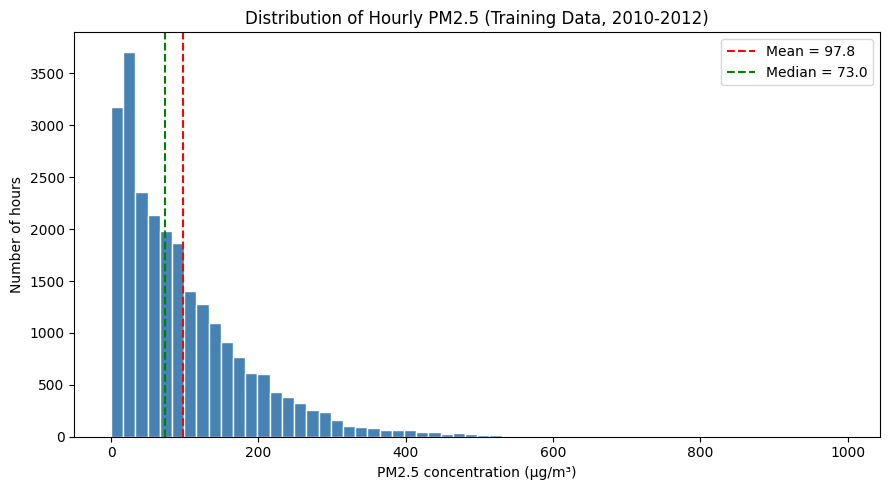

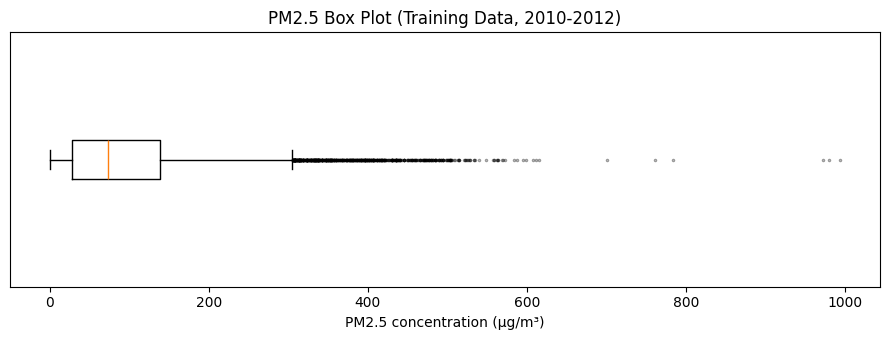

Share of hours above 305.5 (IQR upper fence): 3.26 %


In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

# D2 plot 1: histogram of PM25 with mean/median lines
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(train["PM25"], bins=60, color="steelblue", edgecolor="white")
ax.axvline(train["PM25"].mean(), color="red", linestyle="--",
           label=f"Mean = {train['PM25'].mean():.1f}")
ax.axvline(train["PM25"].median(), color="green", linestyle="--",
           label=f"Median = {train['PM25'].median():.1f}")
ax.set_title("Distribution of Hourly PM2.5 (Training Data, 2010-2012)")
ax.set_xlabel("PM2.5 concentration (µg/m³)")
ax.set_ylabel("Number of hours")
ax.legend()
plt.tight_layout()
plt.savefig("figures/pm25_distribution.png", dpi=150)
plt.show()

# D2 plot 2: box plot
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.boxplot(train["PM25"], vert=False, showfliers=True,
           flierprops=dict(marker=".", markersize=3, alpha=0.4))
ax.set_title("PM2.5 Box Plot (Training Data, 2010-2012)")
ax.set_xlabel("PM2.5 concentration (µg/m³)")
ax.set_yticks([])
plt.tight_layout()
plt.savefig("figures/pm25_boxplot.png", dpi=150)
plt.show()

print("Share of hours above 305.5 (IQR upper fence):",
      round((train["PM25"] > 305.5).mean() * 100, 2), "%")

Figure 1 shows that hourly PM2.5 in the training period is strongly right-skewed (skewness = 1.70). Most hours fall below about 300 µg/m³, with the highest density near 20 to 30 µg/m³, while a long tail extends to nearly 1,000 µg/m³. The mean (97.8) exceeds the median (73.0) because the tail pulls the mean upward, so the median is a better description of a typical hour.


Figure 2 shows that the IQR box lies between roughly 28 and 139 µg/m³, with a median near 73. Using the 1.5 × IQR rule, the upper fence is about 305.5 µg/m³, and many hours exceed it, forming a dense band up to roughly 520 and a few isolated extreme values near 1,000. Because the lower fence is below zero, no low values can be flagged. These flagged hours are statistical outliers, not confirmed errors, and they likely include genuine severe-pollution episodes.

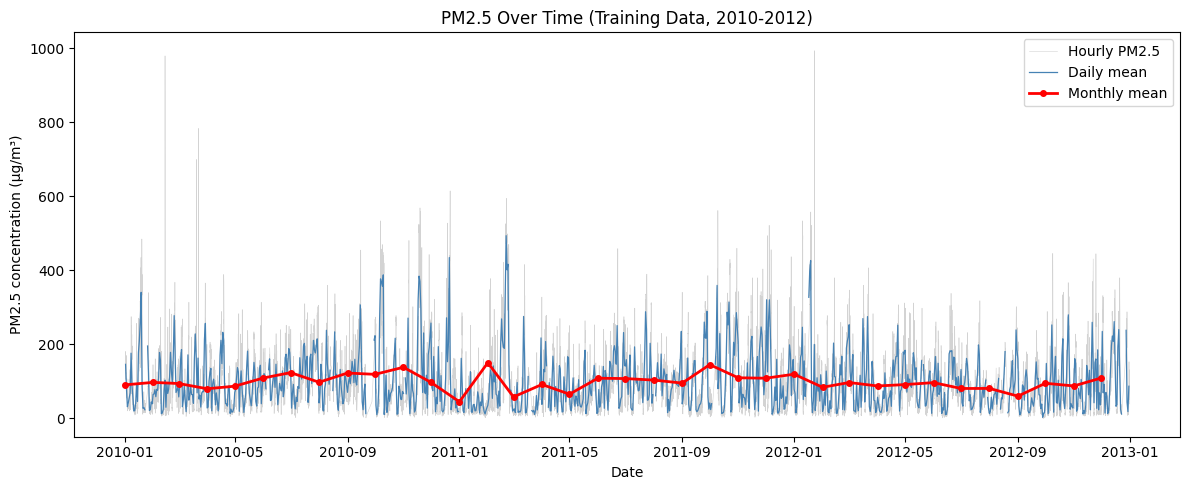

MONTHLY MEAN PM2.5 BY CALENDAR MONTH (training)
month
1      84.8
2     110.3
3      84.2
4      85.9
5      81.1
6     104.4
7     104.6
8      93.8
9      88.7
10    118.2
11    111.3
12    104.8

MEAN PM2.5 BY HOUR OF DAY (training)
hour
0     112.0
1     113.1
2     108.7
3     105.9
4     102.3
5      99.1
6      95.7
7      95.8
8      95.6
9      94.9
10     94.2
11     93.1
12     90.2
13     88.1
14     86.1
15     84.9
16     85.0
17     86.7
18     89.9
19     96.0
20    102.6
21    107.9
22    109.8
23    110.4

Share of hours above 305.5: 3.26 %


In [9]:
ts = train.set_index("timestamp")["PM25"]

daily = ts.resample("D").mean()
monthly = ts.resample("MS").mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ts.index, ts.values, color="lightgray", linewidth=0.4,
        label="Hourly PM2.5")
ax.plot(daily.index, daily.values, color="steelblue", linewidth=0.9,
        label="Daily mean")
ax.plot(monthly.index, monthly.values, color="red", linewidth=2,
        marker="o", markersize=4, label="Monthly mean")
ax.set_title("PM2.5 Over Time (Training Data, 2010-2012)")
ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 concentration (µg/m³)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/pm25_over_time.png", dpi=150)
plt.show()

print("MONTHLY MEAN PM2.5 BY CALENDAR MONTH (training)")
print(train.groupby("month")["PM25"].mean().round(1).to_string())

print("\nMEAN PM2.5 BY HOUR OF DAY (training)")
print(train.groupby("hour")["PM25"].mean().round(1).to_string())

print("\nShare of hours above 305.5:",
      round((train["PM25"] > 305.5).mean() * 100, 2), "%")

Figure 3 shows hourly PM2.5 (grey), daily means (blue) and monthly means (red) for 2010 to 2012. Hourly values fluctuate sharply, with the largest spikes near 1,000 µg/m³ in early 2010 and early 2012, while daily and monthly aggregation smooth the hourly spikes. The separately reported annual means decrease from 104.0 in 2010 to 90.5 in 2012; three years alone do not establish a persistent trend. Calendar-month averages range from 81.1 to 118.2 µg/m³ with no clear winter-summer split, and the January average may be affected by missing data. By hour of day, PM2.5 is highest around 01:00 (113.1) and lowest at 15:00 (84.9), closely followed by 16:00 (85.0).

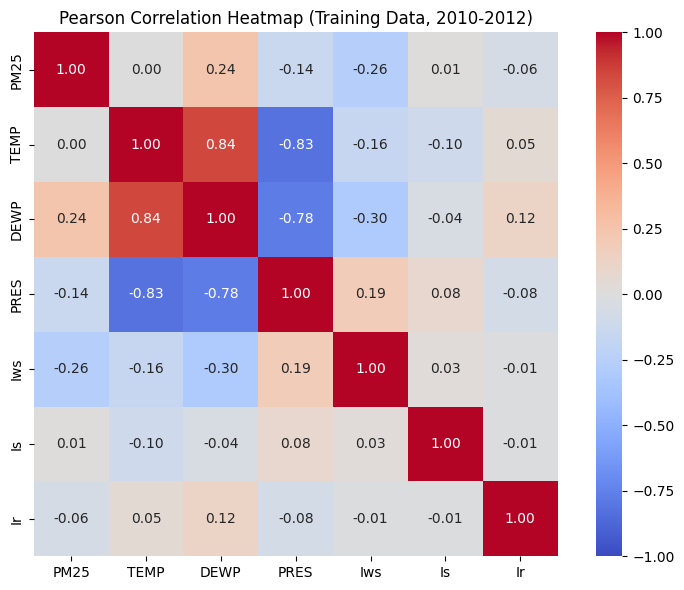

PEARSON CORRELATION WITH PM25
TEMP    0.003
DEWP    0.245
PRES   -0.138
Iws    -0.264
Is      0.011
Ir     -0.055

SPEARMAN CORRELATION WITH PM25
TEMP    0.095
DEWP    0.358
PRES   -0.220
Iws    -0.381
Is      0.038
Ir      0.000


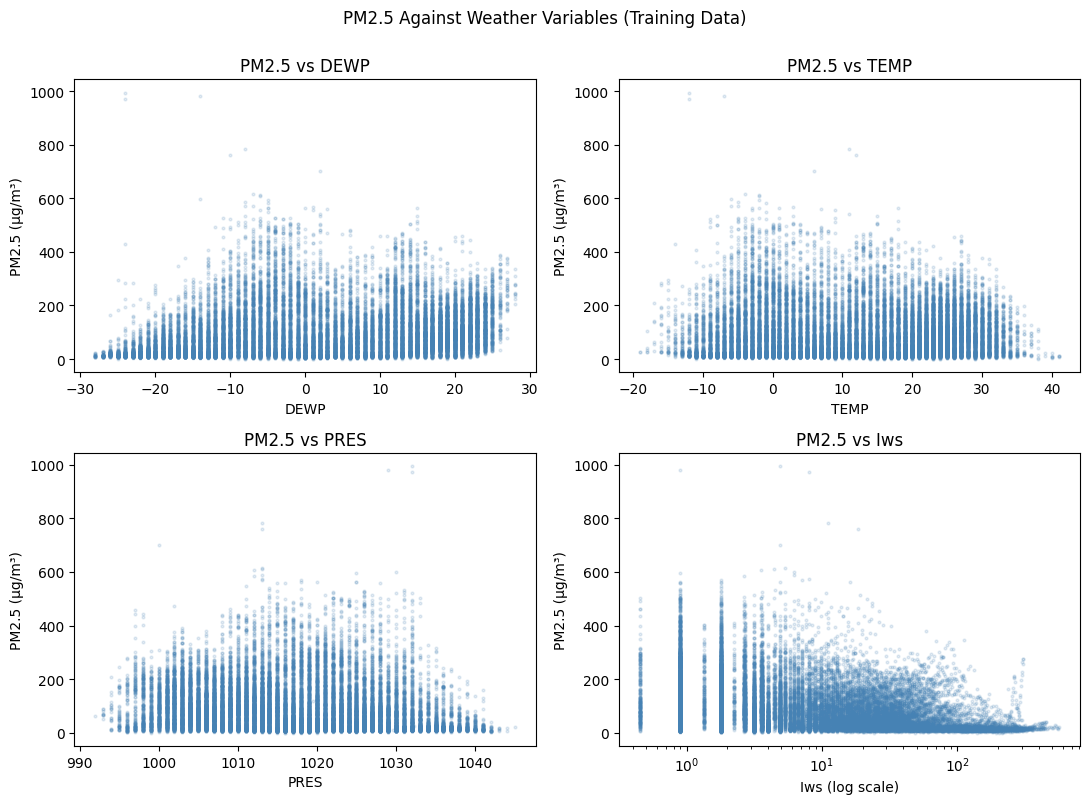


MEAN AND MEDIAN PM25 BY WIND DIRECTION
       mean  median  count
cbwd                      
NE     90.2    54.0   2716
NW     67.4    30.0   8368
SE    113.4    96.0   8362
cv    126.9   100.0   4972

MEAN PM25 BY YEAR
year
2010    104.0
2011     99.1
2012     90.5


In [10]:
import seaborn as sns

corr_cols = ["PM25", "TEMP", "DEWP", "PRES", "Iws", "Is", "Ir"]

# D2 plot 4: correlation heatmap (Pearson)
pearson = train[corr_cols].corr(method="pearson")
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Pearson Correlation Heatmap (Training Data, 2010-2012)")
plt.tight_layout()
plt.savefig("figures/correlation_heatmap.png", dpi=150)
plt.show()

print("PEARSON CORRELATION WITH PM25")
print(pearson["PM25"].drop("PM25").round(3).to_string())
print("\nSPEARMAN CORRELATION WITH PM25")
print(train[corr_cols].corr(method="spearman")["PM25"]
      .drop("PM25").round(3).to_string())

# D2 plot 5: scatter plots against four explanatory variables
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), ["DEWP", "TEMP", "PRES", "Iws"]):
    ax.scatter(train[col], train["PM25"], s=4, alpha=0.15,
               color="steelblue")
    ax.set_xlabel(col + (" (log scale)" if col == "Iws" else ""))
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.set_title(f"PM2.5 vs {col}")
    if col == "Iws":
        ax.set_xscale("log")
fig.suptitle("PM2.5 Against Weather Variables (Training Data)", y=1.0)
plt.tight_layout()
plt.savefig("figures/feature_scatterplots.png", dpi=150)
plt.show()

print("\nMEAN AND MEDIAN PM25 BY WIND DIRECTION")
print(train.groupby("cbwd")["PM25"].agg(["mean", "median", "count"])
      .round(1).to_string())

print("\nMEAN PM25 BY YEAR")
print(train.groupby("year")["PM25"].mean().round(1).to_string())

Figure 4 shows that the numeric weather variables are individually only weakly correlated with PM2.5 (Pearson |r| ≤ 0.264; Spearman up to -0.38 for Iws and +0.36 for DEWP). TEMP, DEWP and PRES are strongly intercorrelated (|r| = 0.78 to 0.84), which is a multicollinearity concern for linear models.

Figure 5 shows non-linear patterns: very high PM2.5 occurs only at low cumulative wind (Iws) and moderate dew point, temperature and pressure. By wind direction, the median PM2.5 is 30 µg/m³ under NW wind versus 100 under calm/variable wind. These are associations, not proof of causation.

### Step 3 Interpretation: Outlier Comparison (IQR vs. Z-Score) and Retention Justification

* **Comparison of Methods:**
  * On training `PM25`, the non-parametric IQR fence (`> 305.5` $\mu\text{g/m}^3$) flags `797` hours (`3.26%`), whereas the parametric Z-score criterion (`|z| > 3`, corresponding to `> 365.6` $\mu\text{g/m}^3$) flags `422` hours (`1.73%`). Every Z-flagged observation is a subset of the IQR-flagged set, leaving `375` hours between `306` and `365` $\mu\text{g/m}^3$ flagged only by IQR.
  * The Z-score criterion is poorly suited to `PM25` and `Iws` because both distributions are heavily right-skewed (`skewness = 1.70` and `3.83`); extreme upper-tail values inflate the sample standard deviation (`89.25` for `PM25`), masking moderate-to-severe pollution hours. Conversely, IQR is unsuitable for zero-inflated `Is` (`99.0%` zeros) and `Ir` (`95.5%` zeros) because `Q1 = Q3 = 0`, which would trivially flag every nonzero precipitation hour. Neither method flags any outliers in `TEMP`, `DEWP`, or `PRES`.
* **Physical Plausibility vs. Sensor Error:**
  * Inspecting the top-5 `PM25` training hours shows consecutive multi-hour trajectories rather than isolated single-hour glitches—for example, `2012-01-23 01:00` and `02:00` (`994` and `972` $\mu\text{g/m}^3$) and `2010-03-22 10:00` and `11:00` (`784` and `761` $\mu\text{g/m}^3$), with `2010-02-14 01:00` (`980` µg/m³) immediately preceding the missing `02:00` observation during an elevated multi-hour episode.
* **Justification of Decisions:**
  1. **Retain all `PM25` extremes:** Deleting the top `3.26%` of hours could remove genuine severe-pollution episodes, artificially cap the target range, and bias evaluations toward clean-air conditions.
  2. **Transform `Iws` via `np.log1p(Iws)`:** Instead of Winsorising or dropping the `2,911` IQR-flagged high-wind hours (`11.92%`), applying $\ln(1 + \text{Iws})$ compresses the right tail (`max = 565.49` $\to$ `6.34`) while preserving rank order.

In [11]:
outlier_cols = ["PM25", "TEMP", "DEWP", "PRES", "Iws"]
rows = []
flag_store = {}

for col in outlier_cols:
    x = train[col]
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = q3 - q1
    iqr_low, iqr_high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    z = (x - x.mean()) / x.std()
    iqr_flag = (x < iqr_low) | (x > iqr_high)
    z_flag = z.abs() > 3
    flag_store[col] = (iqr_flag, z_flag)

    rows.append({
        "variable": col,
        "IQR_low": round(iqr_low, 1), "IQR_high": round(iqr_high, 1),
        "z_low": round(x.mean() - 3 * x.std(), 1),
        "z_high": round(x.mean() + 3 * x.std(), 1),
        "IQR_flagged": int(iqr_flag.sum()),
        "z_flagged": int(z_flag.sum()),
        "both": int((iqr_flag & z_flag).sum()),
        "IQR_only": int((iqr_flag & ~z_flag).sum()),
        "z_only": int((~iqr_flag & z_flag).sum()),
    })

print("OUTLIER COMPARISON (training data)")
print(pd.DataFrame(rows).set_index("variable").to_string())

iqr_f, z_f = flag_store["PM25"]
print("\nPM25 range of IQR-only flagged values:",
      train.loc[iqr_f & ~z_f, "PM25"].min(), "to",
      train.loc[iqr_f & ~z_f, "PM25"].max())

print("\nTOP 5 PM25 HOURS WITH NEIGHBOURS (full hourly timeline)")
for i in train.nlargest(5, "PM25").index:
    print(data.loc[i - 2:i + 2, ["timestamp", "PM25", "Iws", "cbwd"]]
          .to_string(index=False))
    print("-" * 45)

OUTLIER COMPARISON (training data)
          IQR_low  IQR_high  z_low  z_high  IQR_flagged  z_flagged  both  IQR_only  z_only
variable                                                                                  
PM25       -138.5     305.5 -169.9   365.6          797        422   422       375       0
TEMP        -32.0      56.0  -25.2    49.1            0          0     0         0       0
DEWP        -50.0      54.0  -41.9    45.4            0          0     0         0       0
PRES        982.5    1050.5  985.4  1047.8            0          0     0         0       0
Iws         -33.1      59.9 -129.7   182.5         2911        659   659      2252       0

PM25 range of IQR-only flagged values: 306.0 to 365.0

TOP 5 PM25 HOURS WITH NEIGHBOURS (full hourly timeline)
          timestamp  PM25   Iws cbwd
2012-01-22 23:00:00 161.0  0.89   cv
2012-01-23 00:00:00 225.0  3.13   NW
2012-01-23 01:00:00 994.0  4.92   NW
2012-01-23 02:00:00 972.0  8.05   NW
2012-01-23 03:00:00 430.0 11.18

Using training data, the IQR rule flagged 797 PM2.5 hours (3.26%) above 305.5 µg/m³, while |z| > 3 flagged 422 (1.73%) above 365.6. Every z-flagged hour was also IQR-flagged; the 375 IQR-only hours lie between 306 and 365. The z-score threshold is higher because extreme values inflate the standard deviation and PM2.5 is right-skewed (skewness 1.70), so z-scores are not well suited to it. TEMP, DEWP and PRES had no flagged values. Several of the highest PM2.5 hours occurred in consecutive pairs; the 980 µg/m³ reading preceded a missing hour within an elevated episode. These neighbouring observations support retaining the extremes as plausible episodes, but do not prove sensor accuracy. Iws was transformed with log1p rather than trimmed, because it is a cumulative measure.

In [12]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

def add_features(df):
    df = df.copy()
    a, b = 17.625, 243.04   # Magnus-formula constants
    rh = 100 * np.exp(a * df["DEWP"] / (b + df["DEWP"])
                      - a * df["TEMP"] / (b + df["TEMP"]))
    df["rel_humidity"] = rh.clip(upper=100)
    df["log_Iws"] = np.log1p(df["Iws"])
    df["precip_flag"] = ((df["Is"] > 0) | (df["Ir"] > 0)).astype(int)
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
    return df

train_fe = add_features(train)
val_fe = add_features(validation)

numeric_features = ["TEMP", "DEWP", "PRES", "log_Iws", "Is", "Ir",
                    "rel_humidity", "precip_flag",
                    "hour_sin", "hour_cos", "month_sin", "month_cos"]
categorical_features = ["cbwd"]
all_features = numeric_features + categorical_features

X_train, y_train = train_fe[all_features], train_fe["PM25"]
X_val, y_val = val_fe[all_features], val_fe["PM25"]

def make_preprocess():
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ])

def evaluate(pipe, X, y):
    pred = pipe.predict(X)
    mse = mean_squared_error(y, pred)
    return {"MAE": mean_absolute_error(y, pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y, pred)}

models = {
    "Mean baseline": Pipeline([("prep", make_preprocess()),
                               ("model", DummyRegressor(strategy="mean"))]),
    "Linear Regression": Pipeline([("prep", make_preprocess()),
                                   ("model", LinearRegression())]),
}

rows = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)          # fitted on TRAINING data only
    for split, X, y in [("train", X_train, y_train),
                        ("validation", X_val, y_val)]:
        rows.append({"model": name, "split": split, **evaluate(pipe, X, y)})

print("Shapes:", X_train.shape, X_val.shape)
print("Missing inputs in train:", int(X_train.isna().sum().sum()))
print("rel_humidity range (train):",
      round(X_train["rel_humidity"].min(), 1), "to",
      round(X_train["rel_humidity"].max(), 1))
print("\nRESULTS")
print(pd.DataFrame(rows).round(3).to_string(index=False))

Shapes: (24418, 13) (8678, 13)
Missing inputs in train: 0
rel_humidity range (train): 6.1 to 100.0

RESULTS
            model      split    MAE      MSE   RMSE     R2
    Mean baseline      train 67.726 7965.107 89.247  0.000
    Mean baseline validation 70.923 9631.834 98.142 -0.002
Linear Regression      train 48.923 4633.978 68.073  0.418
Linear Regression validation 51.218 5474.136 73.987  0.431


### Deliverable D4: Feature Engineering Notes

All engineered features are computed inside `add_features(df)` as row-wise deterministic transformations of same-hour meteorological and calendar inputs from the [UCI Beijing PM2.5 Dataset](https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data) ([DOI: 10.24432/C5JS49](https://doi.org/10.24432/C5JS49)).

| Engineered Feature | Exact Calculation | Modelling Purpose | Leakage Prevention | Empirical Evidence (Observed vs. Untested) |
| :--- | :--- | :--- | :--- | :--- |
| **`rel_humidity`** | $\min\left(100,\; 100 \times \exp\left(\frac{17.625 \cdot \text{DEWP}}{243.04 + \text{DEWP}} - \frac{17.625 \cdot \text{TEMP}}{243.04 + \text{TEMP}}\right)\right)$ (Magnus approximation, clipped at 100%) | Captures non-linear moisture saturation that promotes hygroscopic particle growth; replaces a simple `DEWP - TEMP` difference, which is redundant for Linear Regression. | Computed row-by-row from same-hour `TEMP` and `DEWP` with no cross-row statistics. | **Group-tested only:** Dropping the combined `{TEMP, DEWP, rel_humidity}` group caused the largest validation RMSE jump (+13.57 $\mu\text{g/m}^3$, from 71.89 to 85.46), and permutation importance increased validation RMSE by +31.01 $\mu\text{g/m}^3$. The standalone gain of `rel_humidity` over raw `TEMP` and `DEWP` was not tested in isolation. |
| **`log_Iws`** | $\ln(1 + \text{Iws})$ via `np.log1p(Iws)` | Compresses extreme right-skewness in cumulative wind run (training skewness = 3.83, median = 6.26 m/s, max = 565.49 m/s) so high-wind hours do not dominate linear fits without deleting true windy observations. | Pointwise logarithmic transform (`Iws >= 0` everywhere); requires no fitted parameters. | **Partially tested:** In training EDA, raw `Iws` has the strongest negative correlation with PM2.5 (Pearson $r = -0.264$, Spearman $\rho = -0.381$). Shuffling `log_Iws` alone increased validation RMSE by +4.98 $\mu\text{g/m}^3$, and dropping `{log_Iws, cbwd}` increased validation RMSE by +1.84 $\mu\text{g/m}^3$ (to 73.73). However, `log_Iws` was not benchmarked head-to-head against raw `Iws` in a separate model fit. |
| **`precip_flag`** | $\mathbb{I}(\text{Is} > 0 \;\lor\; \text{Ir} > 0)$ as an integer (`0` or `1`) | Summarises whether wet deposition (rain or snow washout) is occurring, because raw `Is` (99.0% zeros, skewness 16.86) and `Ir` (95.5% zeros, skewness 11.18) are heavily zero-inflated. | Row-wise boolean check on same-hour `Is` and `Ir` using a fixed threshold of 0. | **Minimal group effect; untested individually:** Shuffling `{Is, Ir, precip_flag}` together changed validation RMSE by only +0.12 $\mu\text{g/m}^3$, and the isolated contribution of `precip_flag` versus raw `Is`/`Ir` was not tested separately. |
| **`hour_sin`, `hour_cos`** | $\sin\left(\frac{2\pi \cdot \text{hour}}{24}\right),\; \cos\left(\frac{2\pi \cdot \text{hour}}{24}\right)$ | Preserves the 24-hour diurnal cycle smoothly so hour 23 and hour 0 are adjacent in feature space, reflecting diurnal boundary-layer and traffic cycles (training mean peaks at 113.1 $\mu\text{g/m}^3$ at 01:00 and troughs at 84.9 $\mu\text{g/m}^3$ at 15:00). | Uses the deterministic calendar period of 24 hours; relies only on the current timestamp. | **Group-tested:** Removing `{hour_sin, hour_cos}` worsened validation RMSE by +1.17 $\mu\text{g/m}^3$ (to 73.06), and shuffling the pair increased validation RMSE by +2.36 $\mu\text{g/m}^3$. Cyclical encoding was not compared against raw integer `hour` or one-hot hour encoding. |
| **`month_sin`, `month_cos`** | $\sin\left(\frac{2\pi \cdot \text{month}}{12}\right),\; \cos\left(\frac{2\pi \cdot \text{month}}{12}\right)$ | Encodes seasonal continuity between December (12) and January (1) to capture seasonal heating and atmospheric stagnation shifts across the year. | Uses the fixed 12-month calendar cycle; relies only on the timestamp's month. | **Group-tested:** Removing `{month_sin, month_cos}` worsened validation RMSE by +4.18 $\mu\text{g/m}^3$ (to 76.07), and removing both month and hour features worsened validation RMSE by +7.63 $\mu\text{g/m}^3$ (to 79.52). Cyclical month encoding was not tested against raw integer `month` or one-hot month dummies. |

#### Leakage Prevention Summary
1. **Chronological Split Before Preprocessing:** The labelled dataset (41,757 rows) was partitioned strictly by year into `train` (2010–2012, $n = 24,418$), `validation` (2013, $n = 8,678$), and `test` (2014, $n = 8,661$) before fitting any statistical transformers.
2. **Row-Wise Feature Engineering:** Every engineered feature in `add_features(df)` is a stateless mathematical function of that exact hour's weather and timestamp—no rolling windows, future leads, or dataset-wide means/quantiles are used, and neither current nor past `PM25` enters `X`.
3. **Training-Only Pipeline Fitting:** Within `make_preprocess()`, the `SimpleImputer(strategy="median")`, `StandardScaler()`, and `OneHotEncoder(handle_unknown="ignore")` are wrapped inside a `scikit-learn` `Pipeline` and fitted exclusively on `X_train`, then applied unchanged to `X_val` and `X_test`.

In [13]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

print("PM25 mean / std  train:", round(y_train.mean(), 1), "/", round(y_train.std(), 1),
      "| validation:", round(y_val.mean(), 1), "/", round(y_val.std(), 1))

lin_pred = models["Linear Regression"].predict(X_val)
print("Linear Regression negative validation predictions:", int((lin_pred < 0).sum()))
print("Training hours with rel_humidity == 100:",
      int((X_train["rel_humidity"] == 100).sum()))

configs = {}
for depth in [3, 5, 8, 12, 16, None]:
    configs[f"Decision Tree (max_depth={depth})"] = DecisionTreeRegressor(
        max_depth=depth, min_samples_leaf=20, random_state=RANDOM_STATE)

for leaf in [5, 20, 50]:
    configs[f"Random Forest (min_samples_leaf={leaf})"] = RandomForestRegressor(
        n_estimators=200, max_features=0.5, min_samples_leaf=leaf,
        random_state=RANDOM_STATE, n_jobs=-1)

tune_rows = []
for name, model in configs.items():
    pipe = Pipeline([("prep", make_preprocess()), ("model", model)])
    pipe.fit(X_train, y_train)                  # training data only
    tr, va = evaluate(pipe, X_train, y_train), evaluate(pipe, X_val, y_val)
    tune_rows.append({"model": name,
                      "train_RMSE": tr["RMSE"], "val_RMSE": va["RMSE"],
                      "train_R2": tr["R2"], "val_R2": va["R2"],
                      "val_MAE": va["MAE"]})

print("\nVALIDATION COMPARISON (sorted by validation RMSE)")
print(pd.DataFrame(tune_rows).sort_values("val_RMSE").round(3).to_string(index=False))

PM25 mean / std  train: 97.8 / 89.2 | validation: 101.7 / 98.1
Linear Regression negative validation predictions: 513
Training hours with rel_humidity == 100: 635

VALIDATION COMPARISON (sorted by validation RMSE)
                              model  train_RMSE  val_RMSE  train_R2  val_R2  val_MAE
Random Forest (min_samples_leaf=20)      52.577    71.889     0.653   0.463   46.972
 Random Forest (min_samples_leaf=5)      39.253    72.200     0.807   0.458   47.061
Random Forest (min_samples_leaf=50)      58.417    72.748     0.572   0.450   47.864
        Decision Tree (max_depth=8)      62.861    76.833     0.504   0.386   50.895
       Decision Tree (max_depth=12)      55.150    79.763     0.618   0.338   50.703
        Decision Tree (max_depth=5)      70.284    80.560     0.380   0.325   54.022
       Decision Tree (max_depth=16)      52.768    80.637     0.650   0.324   51.452
     Decision Tree (max_depth=None)      52.482    80.821     0.654   0.321   51.623
        Decision Tree

Model selection used validation RMSE only, set as the rule before comparing results. The Random Forest (min_samples_leaf=20) had the lowest validation RMSE (71.9 µg/m³), ahead of raw Linear Regression (73.987; 73.430 after clipping negative predictions to zero) and the best Decision Tree (depth 8, 76.8). The improvement is modest, and the three forest settings differ by less than 1 µg/m³, so the choice among them is not strongly supported by a single validation year. The final comparison uses clipped predictions for every model; clipping does not change the selected forest. The documented workflow freezes configurations before final-test evaluation. Earlier exploratory tables use raw predictions and are labelled by this distinction.

In [14]:
rf_pipe = Pipeline([("prep", make_preprocess()),
                    ("model", RandomForestRegressor(
                        n_estimators=200, max_features=0.5,
                        min_samples_leaf=20, random_state=RANDOM_STATE,
                        n_jobs=-1))])
rf_pipe.fit(X_train, y_train)               # training data only
rf_val = rf_pipe.predict(X_val)

# 1. Linear Regression: raw vs clipped at 0 (validation)
lin_val = models["Linear Regression"].predict(X_val)
print("LINEAR REGRESSION ON VALIDATION")
for label, pred in [("raw", lin_val), ("clipped at 0", np.clip(lin_val, 0, None))]:
    mse = mean_squared_error(y_val, pred)
    print(f"{label:13s} MAE={mean_absolute_error(y_val, pred):.3f}  "
          f"RMSE={np.sqrt(mse):.3f}  R2={r2_score(y_val, pred):.3f}")

# 2. Random Forest errors by actual PM2.5 range (validation)
err = pd.DataFrame({"actual": y_val.values, "pred": rf_val})
err["residual"] = err["actual"] - err["pred"]    # positive = underprediction
err["range"] = pd.cut(err["actual"], bins=[-0.1, 35, 75, 150, 250, 1000],
                      labels=["<=35", "35-75", "75-150", "150-250", ">250"])

summary = err.groupby("range", observed=True).agg(
    hours=("actual", "size"),
    mean_actual=("actual", "mean"),
    mean_pred=("pred", "mean"),
    mean_residual=("residual", "mean"),
    MAE=("residual", lambda r: r.abs().mean()))
print("\nRANDOM FOREST (selected) BY ACTUAL PM2.5 RANGE")
print(summary.round(1).to_string())

sq = err["residual"] ** 2
hi = err["actual"] > 250
print(f"\nHours with actual > 250: {hi.mean()*100:.1f}% of hours, "
      f"{sq[hi].sum() / sq.sum() * 100:.1f}% of total squared error")

LINEAR REGRESSION ON VALIDATION
raw           MAE=51.218  RMSE=73.987  R2=0.431
clipped at 0  MAE=49.941  RMSE=73.430  R2=0.439

RANDOM FOREST (selected) BY ACTUAL PM2.5 RANGE
         hours  mean_actual  mean_pred  mean_residual    MAE
range                                                       
<=35      2384         18.6       43.9          -25.3   25.9
35-75     2142         54.9       85.5          -30.6   35.9
75-150    2256        108.3      110.3           -2.1   31.5
150-250   1157        190.7      137.7           53.0   66.1
>250       739        346.3      182.6          163.8  164.3

Hours with actual > 250: 8.5% of hours, 58.0% of total squared error


On validation data, the Random Forest overpredicted low-pollution hours (mean residual -25.3 µg/m³ for actual ≤35) and underpredicted high ones (+163.8 for actual >250). The >250 group is 8.5% of hours but contributes 58.0% of total squared error. Because this grouping uses actual values, it partly reflects regression to the mean and should be read alongside the residual-versus-predicted plot.

MODEL COMPARISON (all splits)
                   model      split    MAE      MSE   RMSE     R2
           Mean baseline      train 67.726 7965.107 89.247  0.000
           Mean baseline validation 70.923 9631.834 98.142 -0.002
           Mean baseline       test 68.893 8747.145 93.526 -0.000
       Linear Regression      train 47.986 4566.759 67.578  0.427
       Linear Regression validation 49.941 5391.951 73.430  0.439
       Linear Regression       test 49.511 5075.071 71.240  0.420
 Decision Tree (depth 8)      train 42.764 3951.541 62.861  0.504
 Decision Tree (depth 8) validation 50.895 5903.359 76.833  0.386
 Decision Tree (depth 8)       test 50.077 5395.474 73.454  0.383
Random Forest (selected)      train 35.419 2764.374 52.577  0.653
Random Forest (selected) validation 46.972 5168.022 71.889  0.463
Random Forest (selected)       test 45.266 4448.241 66.695  0.491


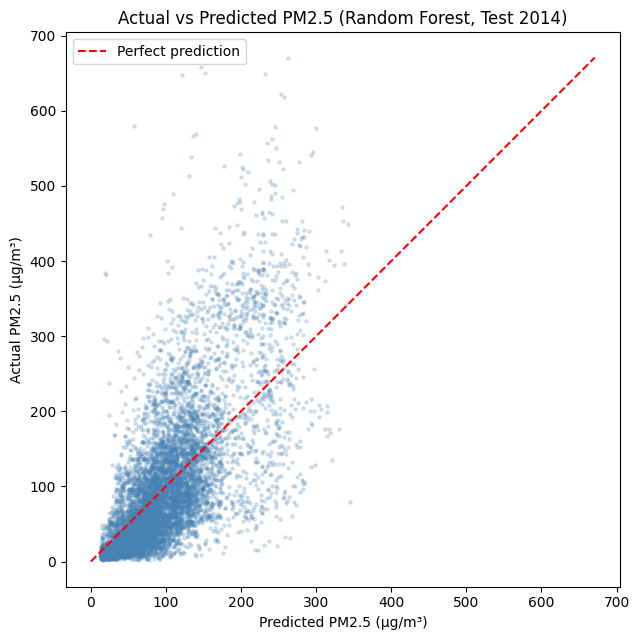

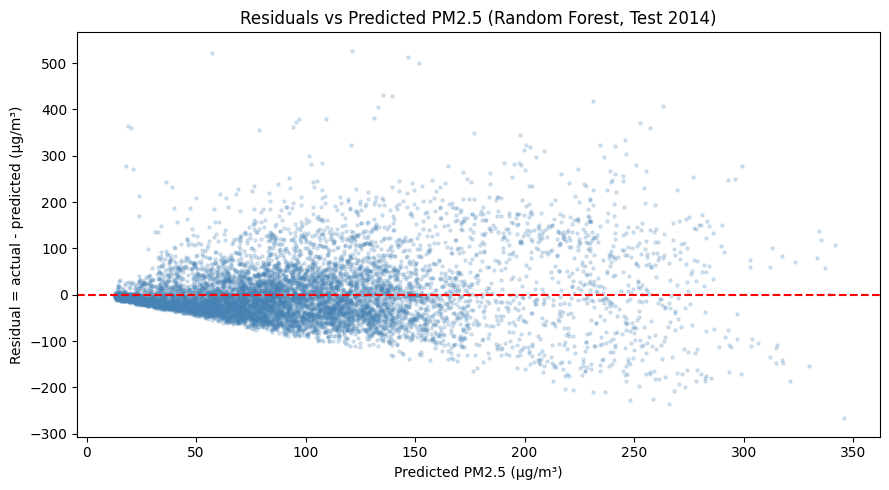


TEST SET FACTS
PM25 mean / std: 97.7 / 93.5
Mean residual (bias): 1.61
Largest prediction: 345.6 | largest actual: 671.0
Actual > 250: 7.7% of hours, 50.5% of squared error


In [15]:
test_fe = add_features(test)
X_test, y_test = test_fe[all_features], test_fe["PM25"]

frozen = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree (depth 8)": DecisionTreeRegressor(
        max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE),
    "Random Forest (selected)": RandomForestRegressor(
        n_estimators=200, max_features=0.5, min_samples_leaf=20,
        random_state=RANDOM_STATE, n_jobs=-1),
}

def scores(y, pred):
    pred = np.clip(pred, 0, None)            # concentrations cannot be negative
    mse = mean_squared_error(y, pred)
    return {"MAE": mean_absolute_error(y, pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y, pred)}

fitted, rows = {}, []
for name, model in frozen.items():
    pipe = Pipeline([("prep", make_preprocess()), ("model", model)])
    pipe.fit(X_train, y_train)               # training data only
    fitted[name] = pipe
    for split, X, y in [("train", X_train, y_train),
                        ("validation", X_val, y_val),
                        ("test", X_test, y_test)]:
        rows.append({"model": name, "split": split, **scores(y, pipe.predict(X))})

results = pd.DataFrame(rows)
results.round(3).to_csv("model_comparison.csv", index=False)
print("MODEL COMPARISON (all splits)")
print(results.round(3).to_string(index=False))

# Required plots for the selected model, on the test set
best = fitted["Random Forest (selected)"]
test_pred = np.clip(best.predict(X_test), 0, None)
resid = y_test.values - test_pred            # positive = underprediction

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(test_pred, y_test, s=5, alpha=0.2, color="steelblue")
lim = max(y_test.max(), test_pred.max())
ax.plot([0, lim], [0, lim], color="red", linestyle="--", label="Perfect prediction")
ax.set_title("Actual vs Predicted PM2.5 (Random Forest, Test 2014)")
ax.set_xlabel("Predicted PM2.5 (µg/m³)")
ax.set_ylabel("Actual PM2.5 (µg/m³)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/actual_vs_predicted.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(test_pred, resid, s=5, alpha=0.2, color="steelblue")
ax.axhline(0, color="red", linestyle="--")
ax.set_title("Residuals vs Predicted PM2.5 (Random Forest, Test 2014)")
ax.set_xlabel("Predicted PM2.5 (µg/m³)")
ax.set_ylabel("Residual = actual - predicted (µg/m³)")
plt.tight_layout()
plt.savefig("figures/residual_plot.png", dpi=150)
plt.show()

print("\nTEST SET FACTS")
print("PM25 mean / std:", round(y_test.mean(), 1), "/", round(y_test.std(), 1))
print("Mean residual (bias):", round(resid.mean(), 2))
print("Largest prediction:", round(test_pred.max(), 1),
      "| largest actual:", round(y_test.max(), 1))
hi = (y_test.values > 250)
print(f"Actual > 250: {hi.mean()*100:.1f}% of hours, "
      f"{(resid[hi]**2).sum() / (resid**2).sum() * 100:.1f}% of squared error")

In [16]:
print("MODEL COMPARISON (all splits)")
print(results.round(3).to_string(index=False))

err = pd.DataFrame({"month": test_fe["month"].values,
                    "actual": y_test.values, "pred": test_pred})
err["residual"] = err["actual"] - err["pred"]
err["pred_range"] = pd.cut(err["pred"], bins=[0, 50, 100, 150, 200, 400],
                           labels=["<=50", "50-100", "100-150", "150-200", ">200"])

print("\nTEST ERRORS BY PREDICTED RANGE")
print(err.groupby("pred_range", observed=True).agg(
    hours=("actual", "size"), mean_actual=("actual", "mean"),
    mean_pred=("pred", "mean"), mean_residual=("residual", "mean"),
    resid_std=("residual", "std"),
    MAE=("residual", lambda r: r.abs().mean())).round(1).to_string())

print("\nTEST ERRORS BY MONTH")
print(err.groupby("month").agg(
    hours=("actual", "size"), mean_actual=("actual", "mean"),
    mean_residual=("residual", "mean"),
    MAE=("residual", lambda r: r.abs().mean()),
    RMSE=("residual", lambda r: np.sqrt((r ** 2).mean()))).round(1).to_string())

MODEL COMPARISON (all splits)
                   model      split    MAE      MSE   RMSE     R2
           Mean baseline      train 67.726 7965.107 89.247  0.000
           Mean baseline validation 70.923 9631.834 98.142 -0.002
           Mean baseline       test 68.893 8747.145 93.526 -0.000
       Linear Regression      train 47.986 4566.759 67.578  0.427
       Linear Regression validation 49.941 5391.951 73.430  0.439
       Linear Regression       test 49.511 5075.071 71.240  0.420
 Decision Tree (depth 8)      train 42.764 3951.541 62.861  0.504
 Decision Tree (depth 8) validation 50.895 5903.359 76.833  0.386
 Decision Tree (depth 8)       test 50.077 5395.474 73.454  0.383
Random Forest (selected)      train 35.419 2764.374 52.577  0.653
Random Forest (selected) validation 46.972 5168.022 71.889  0.463
Random Forest (selected)       test 45.266 4448.241 66.695  0.491

TEST ERRORS BY PREDICTED RANGE
            hours  mean_actual  mean_pred  mean_residual  resid_std    MAE
pred_

On the 2014 test set, the Random Forest had the lowest error (MAE 45.3, RMSE 66.7 µg/m³, R² = 0.491), ahead of Linear Regression (RMSE 71.2) and the depth-8 Decision Tree (73.5). Mean residuals by predicted range stayed between approximately -4.3 and +20.9 µg/m³, but the residual standard deviation grew from 31 to 128 µg/m³ as predictions rose, showing non-constant variance. Errors were largest in February (RMSE 113.4), with underprediction in February (mean residual +58.7) and overprediction in June (-36.7). Changes between years are a possible explanation, rather than a demonstrated cause.

Baseline validation RMSE: 71.889

PERMUTATION IMPORTANCE (validation)
              feature group  RMSE increase (mean)  std
                      Month                 33.25 0.37
Temp / dew point / humidity                 31.01 0.44
  Cumulative wind (log_Iws)                  4.98 0.40
                Hour of day                  2.36 0.14
      Wind direction (cbwd)                  2.08 0.12
            Pressure (PRES)                  0.54 0.25
                Snow / rain                  0.12 0.03


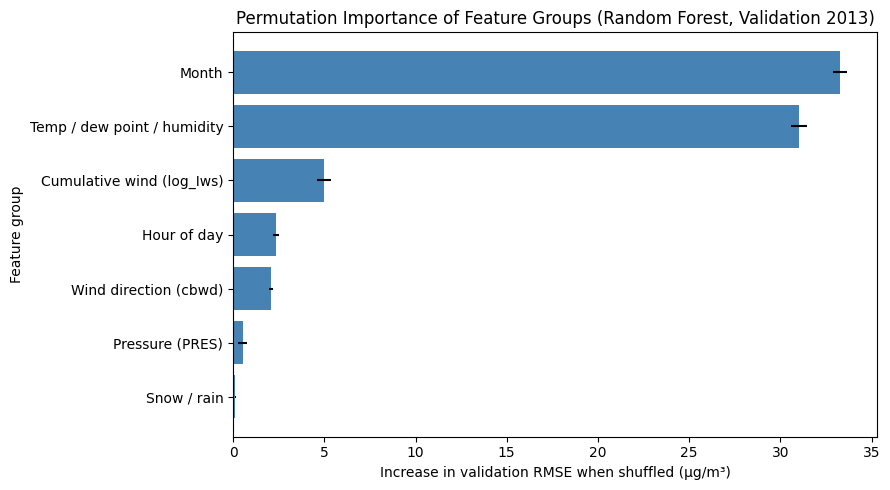

In [17]:
best = fitted["Random Forest (selected)"]       # already fitted on training data
rng = np.random.default_rng(RANDOM_STATE)

groups = {
    "Wind direction (cbwd)": ["cbwd"],
    "Cumulative wind (log_Iws)": ["log_Iws"],
    "Temp / dew point / humidity": ["TEMP", "DEWP", "rel_humidity"],
    "Pressure (PRES)": ["PRES"],
    "Hour of day": ["hour_sin", "hour_cos"],
    "Month": ["month_sin", "month_cos"],
    "Snow / rain": ["Is", "Ir", "precip_flag"],
}

base_rmse = np.sqrt(mean_squared_error(y_val, best.predict(X_val)))
print("Baseline validation RMSE:", round(base_rmse, 3))

rows = []
for name, cols in groups.items():
    increases = []
    for _ in range(5):                           # 5 repeats
        Xp = X_val.copy()
        idx = rng.permutation(len(Xp))           # same shuffle for the whole group
        Xp[cols] = X_val[cols].values[idx]
        rmse = np.sqrt(mean_squared_error(y_val, best.predict(Xp)))
        increases.append(rmse - base_rmse)
    rows.append({"feature group": name,
                 "RMSE increase (mean)": np.mean(increases),
                 "std": np.std(increases)})

imp = pd.DataFrame(rows).sort_values("RMSE increase (mean)", ascending=False)
print("\nPERMUTATION IMPORTANCE (validation)")
print(imp.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
imp_plot = imp.sort_values("RMSE increase (mean)")
ax.barh(imp_plot["feature group"], imp_plot["RMSE increase (mean)"],
        xerr=imp_plot["std"], color="steelblue")
ax.set_title("Permutation Importance of Feature Groups (Random Forest, Validation 2013)")
ax.set_xlabel("Increase in validation RMSE when shuffled (µg/m³)")
ax.set_ylabel("Feature group")
plt.tight_layout()
plt.savefig("figures/permutation_importance.png", dpi=150)
plt.show()

Permutation importance on the 2013 validation data suggested that Month (+33.3 µg/m³ RMSE) and the temperature/dew point/humidity group (+31.0) were most important. Because shuffling correlated features creates unrealistic combinations, I also refitted the forest without each group on the training data. Removing the temperature group raised validation RMSE from 71.9 to 85.5 (+13.6), removing Month raised it to 76.1 (+4.2), and removing Hour or the wind features raised it by about 1 to 2. I interpret this as the model relying mainly on temperature-related weather, with calendar information partly recoverable from other features. These are associations in one validation year; they do not show that temperature or month cause changes in PM2.5.

In [18]:
def fit_eval(drop_cols, label):
    num = [c for c in numeric_features if c not in drop_cols]
    cat = [c for c in categorical_features if c not in drop_cols]
    prep = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    pipe = Pipeline([("prep", prep),
                     ("model", RandomForestRegressor(
                         n_estimators=200, max_features=0.5,
                         min_samples_leaf=20, random_state=RANDOM_STATE,
                         n_jobs=-1))])
    pipe.fit(X_train[num + cat], y_train)          # training data only
    tr = evaluate(pipe, X_train[num + cat], y_train)
    va = evaluate(pipe, X_val[num + cat], y_val)
    return {"features removed": label, "n_features": len(num + cat),
            "train_RMSE": tr["RMSE"], "val_RMSE": va["RMSE"],
            "val_MAE": va["MAE"], "val_R2": va["R2"]}

ablations = [
    ([], "none (reference)"),
    (["month_sin", "month_cos"], "Month"),
    (["hour_sin", "hour_cos"], "Hour"),
    (["month_sin", "month_cos", "hour_sin", "hour_cos"], "Month + Hour"),
    (["TEMP", "DEWP", "rel_humidity"], "Temp / dew point / humidity"),
    (["log_Iws", "cbwd"], "Wind (log_Iws + cbwd)"),
]

abl = pd.DataFrame([fit_eval(d, l) for d, l in ablations])
print("ABLATION (refit without group, validation 2013)")
print(abl.round(3).to_string(index=False))

ABLATION (refit without group, validation 2013)
           features removed  n_features  train_RMSE  val_RMSE  val_MAE  val_R2
           none (reference)          13      52.577    71.889   46.972   0.463
                      Month          11      58.958    76.072   50.496   0.398
                       Hour          11      53.771    73.057   47.671   0.445
               Month + Hour           9      61.915    79.518   53.097   0.342
Temp / dew point / humidity          10      68.382    85.461   59.103   0.241
      Wind (log_Iws + cbwd)          11      54.707    73.733   48.142   0.435


### Step 5 Interpretation: Validation Selection and Held-Out Test Evaluation (Deliverable D3)

| Model | Test MAE ($\mu\text{g/m}^3$) | Test MSE ($\mu\text{g/m}^3$)$^2$ | Test RMSE ($\mu\text{g/m}^3$) | Test $R^2$ | Val RMSE ($\mu\text{g/m}^3$) | Val $R^2$ | Train $R^2$ |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Random Forest (selected)** | **45.27** | **4448.2** | **66.70** | **0.491** | **71.89** | **0.463** | **0.653** |
| Linear Regression (clipped) | 49.51 | 5075.1 | 71.24 | 0.420 | 73.43 | 0.439 | 0.427 |
| Decision Tree (depth 8) | 50.08 | 5395.5 | 73.45 | 0.383 | 76.83 | 0.386 | 0.504 |
| Mean baseline | 68.89 | 8747.1 | 93.53 | -0.000 | 98.14 | -0.002 | 0.000 |

* **Metric Definitions & Physical Clipping:**
  * **MAE** measures the average absolute error in $\mu\text{g/m}^3$ treating all deviations linearly; **MSE** and **RMSE** ($\sqrt{\text{MSE}}$) penalise large errors heavily during severe pollution spikes; **$R^2$** equals 1 minus the model squared-error sum divided by the squared-error sum around the evaluated split's own mean. It is not percentage accuracy and can be negative. The fitted mean baseline instead predicts the training mean, so its validation/test R² need not be zero.
  * Because physical $PM_{2.5}$ concentration cannot be negative, predictions in `scores(y, pred)` are clipped at `0`. Raw Linear Regression predicted negative values on `513` of `8,678` validation hours (`5.9%`), and clipping reduced its validation RMSE from `73.99` to `73.43` $\mu\text{g/m}^3$.
* **Validation Tuning & Selection Rule:**
  * The selection criterion—lowest 2013 validation RMSE—was fixed before inspecting 2014 test scores. Notice that 2013 validation data is more variable (`mean = 101.7`, `std = 98.1`) than 2010–2012 training data (`mean = 97.8`, `std = 89.2`), and its mean differs from the training mean. This mean difference gives the constant training-mean baseline a slightly negative validation $R^2$ (`-0.002`).
  * For the **Decision Tree** (`min_samples_leaf=20`), sweeping `max_depth` on validation showed classic underfitting at shallow depths (`RMSE = 81.99` at depth 3; `80.56` at depth 5), an optimum at `max_depth=8` (`76.83`), and overfitting at deeper trees (`79.76` at depth 12; `80.82` unrestricted).
  * For the **Random Forest** (`n_estimators=200`, `max_features=0.5`), validation RMSE across `min_samples_leaf` values of `5` (`72.20`), `20` (`71.89`), and `50` (`72.75`) differed by less than `1` $\mu\text{g/m}^3$ on a single validation year; `min_samples_leaf=20` was frozen as the selected configuration.
* **Held-Out 2014 Test Performance:**
  * On the unseen 2014 test set (`n = 8,661`, `mean = 97.7`, `std = 93.5`), the frozen **Random Forest** achieves the best performance across every metric (`MAE = 45.27`, `RMSE = 66.70`, `R² = 0.491`).
  * Compared with clipped Linear Regression (`RMSE = 71.24`, `MAE = 49.51`), the Random Forest reduces test RMSE by `6.4%` (`4.54` $\mu\text{g/m}^3$) and MAE by `8.6%` (`4.24` $\mu\text{g/m}^3$) in this evaluation. Non-linear interactions and averaging across 200 trees are plausible explanations for its advantage over a single depth-8 tree (`RMSE = 73.45`). The model squared-error sum is still about 50.9% of the test-mean baseline squared-error sum. Unmeasured emissions and missing weather-history information are possible sources of remaining error; their contributions are not quantified here.

In [19]:
test_tbl = results[results["split"] == "test"].set_index("model")[["MAE", "MSE", "RMSE", "R2"]]
val_tbl = (results[results["split"] == "validation"].set_index("model")[["RMSE", "R2"]]
           .add_prefix("val_"))
train_tbl = results[results["split"] == "train"].set_index("model")[["R2"]].add_prefix("train_")

final_table = test_tbl.join(val_tbl).join(train_tbl)
final_table["selected"] = np.where(final_table.index == "Random Forest (selected)",
                                   "YES (lowest validation RMSE)", "")
final_table = final_table.sort_values("RMSE")

print("D3: MODEL COMPARISON (test = 2014 held-out; val/train shown for context)")
print(final_table.round(3).to_string())

final_table.round(3).to_csv("model_comparison_final.csv")
abl.round(3).to_csv("ablation_validation.csv", index=False)
print("\nSaved: model_comparison_final.csv, ablation_validation.csv")

D3: MODEL COMPARISON (test = 2014 held-out; val/train shown for context)
                             MAE       MSE    RMSE     R2  val_RMSE  val_R2  train_R2                      selected
model                                                                                                              
Random Forest (selected)  45.266  4448.241  66.695  0.491    71.889   0.463     0.653  YES (lowest validation RMSE)
Linear Regression         49.511  5075.071  71.240  0.420    73.430   0.439     0.427                              
Decision Tree (depth 8)   50.077  5395.474  73.454  0.383    76.833   0.386     0.504                              
Mean baseline             68.893  8747.145  93.526 -0.000    98.142  -0.002     0.000                              

Saved: model_comparison_final.csv, ablation_validation.csv


### Deliverable D5: Five Critical Reflections, References & AI Usage Disclosure

#### 1. Why the Selected Model Works Best on This Dataset
* **Observed Facts:** On the 2013 validation set (`n = 8,678`), `RandomForestRegressor(n_estimators=200, max_features=0.5, min_samples_leaf=20)` achieved the lowest validation RMSE (`71.889` $\mu\text{g/m}^3$, `MAE = 46.972`, $R^2 = 0.463$), outperforming clipped `LinearRegression` (`val RMSE = 73.430`) and the best single `DecisionTreeRegressor(max_depth=8)` (`val RMSE = 76.833`). On the held-out 2014 test set (`n = 8,661`), this frozen Random Forest remained best on every metric (`Test RMSE = 66.695` $\mu\text{g/m}^3$, `MAE = 45.266`, `MSE = 4448.241`, $R^2 = 0.491$) versus Linear Regression (`Test RMSE = 71.240`, `MAE = 49.511`, $R^2 = 0.420$), Decision Tree depth 8 (`Test RMSE = 73.454`, `MAE = 50.077`, $R^2 = 0.383$), and the constant training-mean baseline (`Test RMSE = 93.526`, `MAE = 68.893`, $R^2 = -0.000$).
* **Hypotheses:** Urban $PM_{2.5}$ responds to threshold-like regime interactions—such as stagnant southerly/calm wind (`cbwd` in `{SE, cv}` with low `log_Iws`) combined with high moisture (`DEWP` and `rel_humidity`) during autumn/winter inversions—that additive hyperplane models (`LinearRegression`) cannot represent, while also avoiding the `513` negative validation predictions (`5.9%` of validation hours) made by unclipped Linear Regression.
* **Conclusions & Decisions:** Averaging 200 decorrelated trees (`max_features=0.5`, `min_samples_leaf=20`) captures multi-variable meteorological interactions while reducing the high variance of a single tree (`val RMSE = 71.889` vs. `76.833`). Note that the three Random Forest leaf settings (`min_samples_leaf` in `{5, 20, 50}`) differed by less than `0.9` $\mu\text{g/m}^3$ on a single validation year (`72.200`, `71.889`, `72.748`), so the specific choice of `20` over `5` or `50` is modest.

#### 2. Which Features Drive Predictions Most — and Why
* **Observed Facts:** On 2013 validation data (`baseline RMSE = 71.889` $\mu\text{g/m}^3$), grouped permutation importance ranked `Month` (`+33.25 ± 0.37` $\mu\text{g/m}^3$ RMSE increase) and `Temp / dew point / humidity` (`+31.01 ± 0.44` $\mu\text{g/m}^3$) highest, followed by `log_Iws` (`+4.98 ± 0.40`), `Hour of day` (`+2.36 ± 0.14`), `cbwd` (`+2.08 ± 0.12`), `PRES` (`+0.54 ± 0.25`), and `Snow / rain` (`+0.12 ± 0.03`). However, because `TEMP`, `DEWP`, and `PRES` are strongly correlated (`|r| = 0.78` to `0.84`) and calendar month may also share seasonal information, shuffling one group while holding the others fixed can create combinations poorly represented in the observed data (e.g., January month encoding paired with `+30°C` summer temperature and dew point). When refitting the Random Forest from scratch on training data without each group (ablation), removing `{TEMP, DEWP, rel_humidity}` caused the largest validation RMSE increase (`+13.572` $\mu\text{g/m}^3$, to `85.461`, $R^2 = 0.241$), whereas removing `Month` alone raised validation RMSE by `+4.183` (`76.072`), removing `Month + Hour` raised it by `+7.629` (`79.518`), removing `Wind (log_Iws + cbwd)` raised it by `+1.844` (`73.733`), and removing `Hour` raised it by `+1.168` (`73.057`).
* **Hypotheses:** Thermodynamic and moisture variables (`TEMP`, `DEWP`, `rel_humidity`) carry the primary non-redundant signal because they reflect both seasonal air-mass regimes and same-hour hygroscopic aerosol growth, whereas calendar `Month` is partially recoverable from temperature and pressure when removed.
* **Conclusions & Decisions:** Reporting both permutation importance and refit ablation prevents misinterpreting collinearity artifacts. We treat these importance scores strictly as predictive associations in the 2010–2013 data, not proof of direct physical causation.

#### 3. Where the Model Fails & Systematic Error Regimes
* **Observed Facts:** On the 2014 test set (`actual max = 671.0` $\mu\text{g/m}^3$), the Random Forest's largest prediction on this test set is `345.6` $\mu\text{g/m}^3$, with an overall mean residual (`actual - predicted`) of `+1.61` $\mu\text{g/m}^3$. Grouping test hours by *predicted* range shows heteroscedastic error variance (`residual std` grows from `31.0` $\mu\text{g/m}^3$ for predicted `<= 50` to `50.8` for `50–100`, `70.8` for `100–150`, `100.6` for `150–200`, and `127.5` for `> 200`, while `mean_residual` shifts from `-4.3` to `+20.9` $\mu\text{g/m}^3$). Grouping by *actual* $PM_{2.5}$ shows that hours with actual $PM_{2.5} > 250$ $\mu\text{g/m}^3$ represent `7.7%` of test hours (`8.5%` of validation hours) but account for `50.5%` of total test squared error (`58.0%` on validation, where mean residual for `> 250` is `+163.8` $\mu\text{g/m}^3$). Across 2014 calendar months, test RMSE is worst in February (`113.4` $\mu\text{g/m}^3$, `mean actual = 174.6`, `mean residual = +58.7`) and January (`98.2` $\mu\text{g/m}^3$, `mean actual = 118.6`, `mean residual = +21.9`), and lowest in May (`36.0`) and August (`36.8`), while June is systematically overpredicted (`mean actual = 59.1`, `mean residual = -36.7`).
* **Hypotheses:** Severe haze episodes (`> 350` $\mu\text{g/m}^3$) are driven by multi-day regional accumulation and episodic emissions that same-hour airport weather cannot distinguish from ordinary humid/calm hours. In addition, averaging training targets within leaves and across trees can smooth rare extremes; `min_samples_leaf=20` does not establish a universal prediction cap of 345.6, and inter-annual shifts in monthly pollution (e.g., February 2014 averaging `174.6` vs. `110.3` $\mu\text{g/m}^3$ in 2010–2012 training) induce systematic monthly bias.
* **Conclusions & Decisions:** Evaluating errors by both *predicted* range and *actual* range helps distinguish non-constant error spread from patterns introduced by grouping on actual outcomes. It does not fully identify the causes of underprediction. In deployment, this model should not be used as a standalone alarm for extreme (`> 300` $\mu\text{g/m}^3$) episodes without autoregressive or upwind sensor inputs.

#### 4. Missing Values, Outliers, and Evaluation Integrity
Missing PM2.5 labels were excluded instead of being replaced with invented targets; the original hourly table was retained to examine missingness. This leaves unequal coverage across months, so the measured-hour analysis may not represent the missing hours. The IQR and Z-score rules flagged 797 and 422 training PM2.5 observations respectively; plausible extremes were retained to avoid removing the severe episodes the model should handle. The right-skewed cumulative wind measure was log-transformed rather than trimmed. Input imputation is fitted on training data only, but no selected inputs are missing in the saved training data.

**Leakage and evaluation audit**
* **Observed Facts:** (1) All `2,067` unlabelled `PM25` rows (`4.72%`) were dropped prior to splitting rather than interpolated across time; (2) the labelled dataset (`41,757` rows) was split strictly chronologically into `train` (2010–2012, `n = 24,418`), `validation` (2013, `n = 8,678`), and `test` (2014, `n = 8,661`); (3) all 7 engineered features in `add_features(df)` are stateless row-wise functions of same-hour weather and calendar timestamps, with zero target lags; (4) `SimpleImputer(strategy="median")`, `StandardScaler()`, and `OneHotEncoder(handle_unknown="ignore")` were encapsulated inside a `scikit-learn` `ColumnTransformer` and `Pipeline` fitted solely on `X_train`; and (5) the documented selection rule uses 2013 validation RMSE, with frozen configurations evaluated on 2014. Saved notebook cells do not independently establish that test results were never inspected during earlier development.
* **Hypotheses:** Random k-fold splits mix earlier and later observations and may give optimistic estimates for deployment on a future year because neighbouring hours are dependent. Fitting imputation or scaling before splitting separately risks leaking evaluation-distribution information. The current task is same-hour estimation evaluated across years, not a future-hour forecast.
* **Conclusions & Decisions:** Chronological partitioning and training-only preprocessing reduce leakage risk. The reported 2014 test metrics (`RMSE = 66.695` $\mu\text{g/m}^3$, $R^2 = 0.491$) describe performance on a later calendar year under the documented workflow. Once test results have been inspected, further model changes require a new untouched evaluation period for an independent final assessment.

#### 5. Concrete Roadmap for Future Improvement
* **Observed Facts:** The current same-hour meteorological pipeline leaves `50.9%` of 2014 test variance unexplained ($R^2 = 0.491$) and has a largest observed test prediction of `345.6` $\mu\text{g/m}^3$.
* **Hypotheses & Proposed Extensions:**
  1. **Lagged Weather Trajectory Features (Same-Hour Estimation Without Target Sensors):** Incorporate 6h, 12h, and 24h rolling means and pressure/dew-point tendencies ($\Delta\text{PRES}_{24h}, \Delta\text{DEWP}_{24h}$) plus duration of calm/southerly wind spells (`cbwd in {SE, cv}`) to capture multi-day stagnation build-up using weather data alone.
  2. **Autoregressive Forecasting Mode (When Real-Time $PM_{2.5}$ Telemetry Is Available):** For a true $t+1$ or $t+24$ operational forecast, include lagged $PM_{2.5}$ ($t-1, t-3, t-24$) and rolling 24h $PM_{2.5}$ means while respecting the forecast horizon cutoff.
  3. **Tail-Aware Models & Loss Functions:** Benchmark Gradient Boosted Trees (`HistGradientBoostingRegressor` / LightGBM) with quantile or asymmetric loss to reduce severe-episode underprediction, and expand to multi-station datasets such as the [UCI Beijing Multi-Site Air-Quality Data (ID 501)](https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data) to investigate more local weather–pollution relationships, after checking the location and measurement alignment of each station.

---

### References & AI Usage Disclosure
1. **Dataset Source:** [UCI Machine Learning Repository — Beijing PM2.5 Data (ID 381)](https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data), [DOI: 10.24432/C5JS49](https://doi.org/10.24432/C5JS49).
2. **Primary Literature Citation:** [Liang, X., Zou, T., Guo, B., Li, S., Zhang, H., Zhang, S., Huang, H., & Chen, S. X. (2015). Assessing Beijing's $PM_{2.5}$ pollution: severity, weather impact, APEC and winter heating. *Proceedings of the Royal Society A*, 471(2182), 20150257](https://royalsocietypublishing.org/rspa/article/471/2182/20150257/57659/Assessing-Beijing-s-PM2-5-pollution-severity).
3. **Meteorological Formula Reference:** [Alduchov, O. A., & Eskridge, R. E. (1996). Improved Magnus Form Approximation of Saturation Vapor Pressure. *Journal of Applied Meteorology*, 35(4), 601–609](https://journals.ametsoc.org/view/journals/apme/35/4/1520-0450_1996_035_0601_imfaos_2_0_co_2.xml).
4. **AI Usage Disclosure:** In accordance with the CFA Club IIT Indore Induction Task 2026 guidelines, an AI coding mentor (Gemini) was used to assist with `scikit-learn` pipeline structuring, grouped permutation vs. ablation diagnostic design, and formatting of documentation tables and report layout. ChatGPT also assisted with the step-by-step coding discussion, interpretation, notebook review, and corrections to documentation. This correction pass checked the code and saved outputs and preserved all executable cells and results; it did not rerun the analysis. The author remains responsible for understanding the implementation and verifying reproducibility before submission.